# Events from a behaviour log

Often, the eye tracker gets only some of the events of an experiment, for example a trigger at the start of each trial. The times of stimuli and responses, and everything else about the trials (conditions, choices, reaction times), are then in the log file of the experiment software (e.g., PsychoPy, Psychtoolbox or Presentation).

This notebook shows how to get these events into the eye-tracking data:

1. read the behaviour log and turn its columns into events (`Events.from_table()`),
2. map the times from the clock of the experiment computer to the clock of the eye tracker (`pp.sync_clocks()`), using moments that are in both logs,
3. add the events to the data (`add_events()`) and check the result.

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## The data

We use one participant of the RLMW study (a reinforcement-learning task with mind-wandering probes), the same EDF file as in the [notebook on reading EDF files](importdata_edf.ipynb). The behaviour log of this participant is in the [OSF project of the study](https://osf.io/ca95r/). We download both into the folder `example_data` (only the first time):

In [2]:
d = pp.EyeData.from_eyelink("https://osf.io/trsuq/download",
                            cache_file="example_data/test.edf")
fname = pp.fetch_url("https://osf.io/download/658189c19513840728238876/",
                     cache_file="example_data/010_rlmw_behaviour.csv")

pp: 17:52:03 | INFO     | fetch_url:451 | Using cached copy of 'https://osf.io/trsuq/download': example_data/test.edf


pp: 17:52:03 | INFO     | _read_edf:720 | Loading EDF file: example_data/test.edf (current log level: INFO, set to DEBUG to see eyelinkio output)


pp: 17:52:13 | INFO     | from_eyelink:1741 | Filtering out Eyelink triggers


pp: 17:52:13 | INFO     | fetch_url:451 | Using cached copy of 'https://osf.io/download/658189c19513840728238876/': example_data/010_rlmw_behaviour.csv


The behaviour log was written by PsychoPy. It is a table with one row per trial (the first line is a comment with information about the session):

In [3]:
behav = pd.read_csv(fname, comment="#")
behav.head()

,subj,tasktime,trialtime,trial,probetrial,fixcross_duration,left,right,choice,rt,lreward,rreward,reward
0,10,0.000038,3.600173,1,0,200,1,5,0,-1.000000,4,6,0
1,10,3.604168,3.600156,2,0,200,6,4,6,0.388822,18,18,18
2,10,7.208135,3.600159,3,0,200,2,3,3,0.966059,1,8,8
3,10,10.811549,3.600154,4,0,800,6,5,6,0.607932,18,4,18
4,10,14.414900,3.600182,5,0,200,6,2,6,0.648074,18,7,18


The columns we need are:

- `tasktime`: start of the trial (onset of the fixation cross), in seconds since the start of the task, on the clock of the experiment computer
- `fixcross_duration`: how long the fixation cross was shown before the stimulus (in ms)
- `rt`: reaction time from stimulus onset (in seconds; `-1` if there was no response)
- `probetrial`: 0 for choice trials; for mind-wandering probes, the number of the probe

There are 300 choice trials and 30 probes:

In [4]:
len(behav), (behav.probetrial == 0).sum()

(330, np.int64(300))

## The events in the recording

In this experiment, many events were sent to the eye tracker: the fixation cross (`F_<trial>`), the stimulus (`S_...`), the choice (`C_...`), the reward (`R_...`) and the probes (`P_...`, `CP_...`, `RP_...`):

In [5]:
events = d.events
events[:10]

,Onset (ms),Label
0,0.0,DISPLAY_COORDS = 0 0 1279 1023
1,8340.0,experiment_start
2,8360.0,F_1
3,8560.0,S_1_1_5
4,10560.0,C_1_0_0
5,10576.0,R_1_0
6,11959.0,F_2
7,12159.0,S_2_6_4
8,12548.0,C_2_6_1
9,12775.0,R_2_18


`event_onset()` gives the time of a single event, e.g., the start of the experiment. It raises an error unless exactly one event has the label:

In [6]:
d.event_onset("experiment_start", units="sec")

8.34

To show the more common case, we keep only the fixation-cross events, as if only a trigger at the start of each trial had been sent. We keep the original events to check our result at the end:

In [7]:
orig = d.events
d = d.set_events(orig.filter("F_"))
d.events[:5]

,Onset (ms),Label
0,8360.0,F_1
1,11959.0,F_2
2,15557.0,F_3
3,19156.0,F_4
4,22771.0,F_5


## Events from the behaviour log

The stimulus appeared `fixcross_duration` ms after the start of the trial, and the response came `rt` seconds after the stimulus. We compute both times for the choice trials, with `NaN` for trials without a response:

In [8]:
trials = behav[behav.probetrial == 0].copy()
trials["rt"] = trials.rt.where(trials.rt > 0)     # -1 (no response) -> NaN
stim_on = trials.tasktime + trials.fixcross_duration / 1000

`Events.from_table()` turns these columns into events. The keys of the dict are the labels; the values are column names of the table or arrays of times. Times that are `NaN` give no event, so there are two responses fewer than stimuli. Other columns of the table can be kept as metadata of the events with `meta` (see the [event metadata tutorial](event_metadata.ipynb)): every event of a row gets the values of that row, and the column `row` gives the row in the table:

In [9]:
ev = pp.Events.from_table(trials, {"stim": stim_on,
                                   "response": stim_on + trials.rt},
                          units="sec", meta=["trial", "choice", "reward", "rt"])
ev[0:10]

,Onset (sec),Label,trial,choice,reward,rt,row
0,0.200038,stim,1,0,0,NaN,0
1,3.804168,stim,2,6,18,0.388822,1
2,4.192990,response,2,6,18,0.388822,1
3,7.408135,stim,3,3,8,0.966059,2
4,8.374194,response,3,3,8,0.966059,2
5,11.611549,stim,4,6,18,0.607932,3
6,12.219481,response,4,6,18,0.607932,3
7,14.614900,stim,5,6,18,0.648074,4
8,15.262974,response,5,6,18,0.648074,4
9,18.518260,stim,6,2,9,1.005230,5


These times are still on the clock of the experiment computer. Its zero is the start of the task, while the eye tracker has its own zero point. We cannot add the events yet.

## Synchronizing the clocks

To map one clock to the other, we need moments that are in both logs. Here, these are the trial starts: `tasktime` in the behaviour log and the `F_` events in the recording. There is one of each per trial (including the probes), in the same order:

In [10]:
fix = d.events.filter("F_")
len(behav.tasktime), len(fix)

(330, 330)

`pp.sync_clocks()` pairs them by order and fits a linear map: an offset (the different zero points) and a slope (the clocks run at slightly different speeds, so they drift apart). The units of the trial starts are given with `src_units`; the `F_` events have their own units (ms):

In [11]:
sync = pp.sync_clocks(behav.tasktime, fix, src_units="sec")
sync

pp: 17:52:13 | INFO     | sync_clocks:1439 | sync_clocks(): offset=8352.59 ms, drift=-72.1 ms/h, max |residual|=17.7 ms (n=330)


pp: 17:52:13 | WARNING  | sync_clocks:1448 | sync_clocks(): 127 of 330 residuals larger than 5 ms (pairs [0, 3, 8, 11, 12, ...]); are the times paired correctly?


ClockSync(sec -> ms): offset=8352.59 ms, drift=-72.1 ms/h, max |residual|=17.7 ms (n=330)
           src            dst   residual
       3.8e-05           8360       7.38
       3.60417          11959       2.32
       7.20814          15557      -3.58
       10.8115          19156      -7.92
       14.4149          22771        3.8
  ... (320 more)
       1171.43        1179760       3.27
       1175.03        1183358      -3.45
       1178.64        1186974       7.76
       1182.24        1190572      0.708
       1185.85        1194171      -4.65

The summary shows the offset, the drift (here, the eye-tracker clock loses about 72 ms per hour against the experiment computer) and the largest *residual*. The residuals are the differences between the times in the recording and the mapped times from the log. They are the check that the pairs are right.

Here, `sync_clocks()` warns because some residuals are larger than the default tolerance of 5 ms. Plotting them shows why:

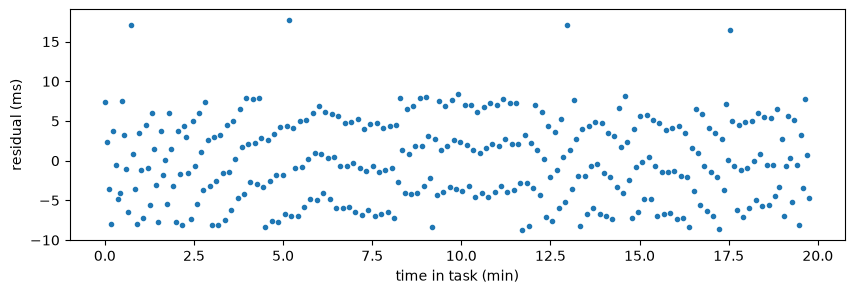

In [12]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(sync.src / 60, sync.residuals, ".")
ax.set_xlabel("time in task (min)")
ax.set_ylabel("residual (ms)");

The residuals are spread evenly between about -10 and +10 ms, with no trend over time. This is not a problem with the pairing: PsychoPy logged `tasktime` at a slightly different moment than the trigger was sent, and the difference varies by up to about one screen frame (17 ms at 60 Hz). Each mapped time is therefore off by up to about 10 ms, but there is no systematic error. With a tolerance that allows for this, there is no warning:

In [13]:
sync = pp.sync_clocks(behav.tasktime, fix, src_units="sec", tol=20 * u.ms)

pp: 17:52:13 | INFO     | sync_clocks:1439 | sync_clocks(): offset=8352.59 ms, drift=-72.1 ms/h, max |residual|=17.7 ms (n=330)


How large the residuals are depends on how the times were logged. Times taken at the screen flip (e.g., the return value of `win.flip()` in PsychoPy or `Screen('Flip')` in Psychtoolbox) usually agree with the trigger within 1–2 ms.

This shows why it is usually a good idea to send the triggers directly to the eye-tracker from within the stimulus-presentation script.

## Adding the events

Calling the fitted map on the events gives them on the clock of the eye tracker (with their metadata). `add_events()` adds them to the events of the recording and sorts all events by onset. The `F_` events have no metadata, so their values are missing:

In [14]:
sync(ev)[0:10]

,Onset (ms),Label,trial,choice,reward,rt,row
0,8552.620039,stim,1,0,0,NaN,0
1,12156.677822,stim,2,6,18,0.388822,1
2,12545.492031,response,2,6,18,0.388822,1
3,15760.572609,stim,3,3,8,0.966059,2
4,16726.612251,response,3,3,8,0.966059,2
5,19963.902384,stim,4,6,18,0.607932,3
6,20571.822202,response,4,6,18,0.607932,3
7,22967.193205,stim,5,6,18,0.648074,4
8,23615.254219,response,5,6,18,0.648074,4
9,26870.474992,stim,6,2,9,1.005230,5


In [15]:
d = d.add_events(sync(ev))
d.events[:8]

,Onset (ms),Label,trial,choice,reward,rt,row
0,8360.000000,F_1,NaN,NaN,NaN,NaN,NaN
1,8552.620039,stim,1.0,0.0,0.0,NaN,0.0
2,11959.000000,F_2,NaN,NaN,NaN,NaN,NaN
3,12156.677822,stim,2.0,6.0,18.0,0.388822,1.0
4,12545.492031,response,2.0,6.0,18.0,0.388822,1.0
5,15557.000000,F_3,NaN,NaN,NaN,NaN,NaN
6,15760.572609,stim,3.0,3.0,8.0,0.966059,2.0
7,16726.612251,response,3.0,3.0,8.0,0.966059,2.0


Because the eye tracker also got the stimulus triggers in this experiment, we can check the result: the stimulus onsets from the behaviour log agree with the `S_` events within about ±9 ms, a few within 18 ms (the jitter we saw in the residuals):

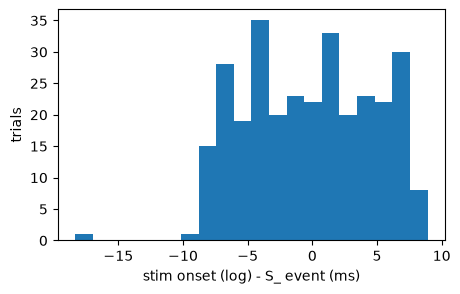

In [16]:
err = d.events.filter("stim", exact=True).onsets - orig.filter("S_").onsets

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(err, bins=20)
ax.set_xlabel("stim onset (log) - S_ event (ms)")
ax.set_ylabel("trials");

## Using the events

The new events work like all other events. For example, the pupil data from 2 to 2.5 minutes, with the fixation-cross, stimulus and response events:

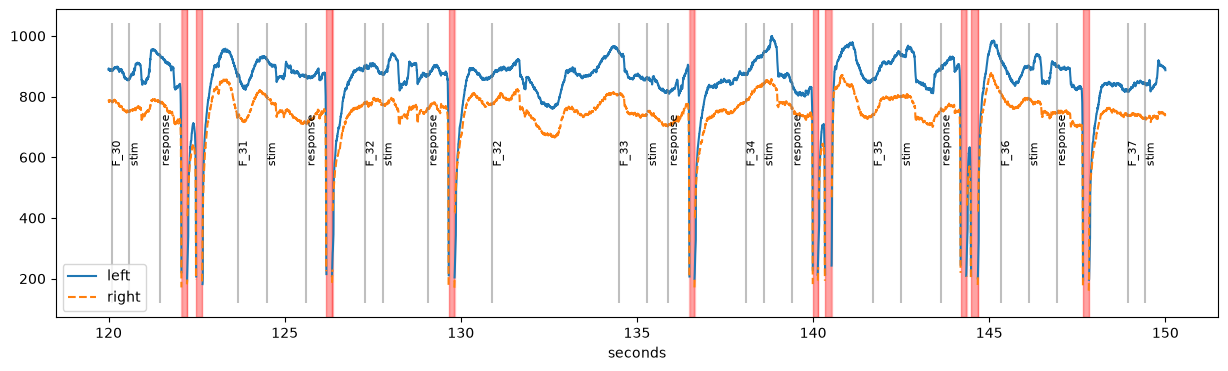

In [17]:
plt.figure(figsize=(15, 4))
d.plot.pupil_plot(plot_range=(2, 2.5) * u.min, units="sec")

The events from the log carry the information about their trial, so they can be selected by it, and `get_intervals()` passes it on to the intervals. Here, the mean pupil size in the second after each stimulus, in a table with the metadata of the stimulus events:

In [18]:
iv = d.get_intervals(d.events.filter("stim", exact=True), window=(0, 1000) * u.ms)
pupil = d.stat_per_event(intervals=iv, eyes="left", variables="pupil")

table = iv.as_pandas()
table["pupil"] = pupil["left_pupil"]
table[["trial", "choice", "rt", "reward", "pupil"]].head()

,trial,choice,rt,reward,pupil
0,1.0,0.0,NaN,0.0,832.528000
1,2.0,6.0,0.388822,18.0,1018.716157
2,3.0,3.0,0.966059,8.0,887.991342
3,4.0,6.0,0.607932,18.0,855.376000
4,5.0,6.0,0.648074,18.0,963.724000


Selections work in the same way, e.g., the stimuli of the trials with a fast response:

In [19]:
d.events.filter("stim", exact=True, rt=lambda rt: rt < 0.5)

,Onset (ms),Label,trial,choice,reward,rt,row
0,12156.677822,stim,2.0,6.0,18.0,0.388822,1.0
1,88440.980264,stim,22.0,4.0,14.0,0.498977,21.0
2,105858.858250,stim,26.0,3.0,18.0,0.496314,25.0


For event-related analyses, see the notebooks on [intervals](intervals.ipynb) and on [event-related pupil dilation](erpds.ipynb).